# 09 · Business Insights & Conclusion

## Objective
Translate the analysis and the final model into **business insights and actions**:
1. Which factors drive the model's churn predictions?
2. How should the retention team use the model's scores?
3. What are the limitations, and what should be done next?

> **Association ≠ causation.** Everything here is learned from observational data. A factor that is
> *associated* with churn (e.g. fiber optic) is not proven to *cause* churn. Recommendations below are
> hypotheses to be tested (ideally with controlled experiments / A/B tests).

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use src/churn_utils.py
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

from src.churn_utils import MODELS_DIR, RANDOM_STATE, load_split, set_plot_style

set_plot_style()
X_train, X_test, y_train, y_test = load_split()
artifact = joblib.load(MODELS_DIR / "best_model.pkl")
pipeline, threshold = artifact["pipeline"], artifact["threshold"]
print(artifact["model_name"], "| threshold =", threshold)

Logistic Regression | threshold = 0.25


## 1. Which features matter most? (permutation importance)

Permutation importance measures how much the test ROC-AUC **drops when one original feature is randomly
shuffled**. It works on the 19 original columns (not the 40 one-hot columns), so it is easy to read, and it
is less affected by correlated one-hot columns than raw coefficients.

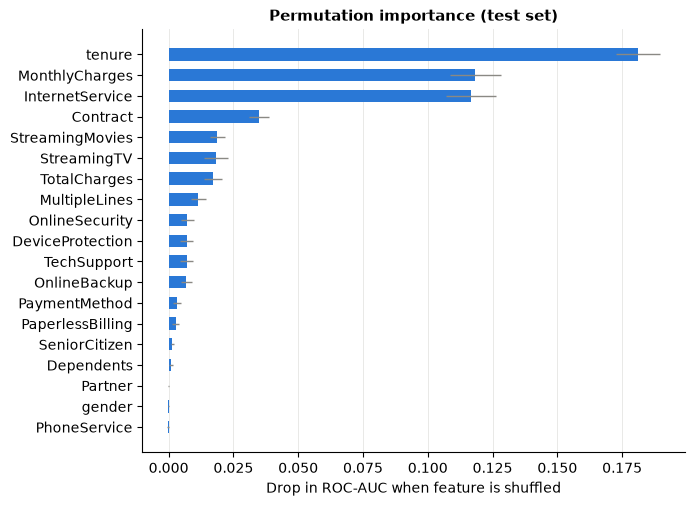

,mean_auc_drop,std
tenure,0.1811,0.0086
MonthlyCharges,0.1183,0.0099
InternetService,0.1167,0.0098
Contract,0.0349,0.0039
StreamingMovies,0.0188,0.0030
StreamingTV,0.0184,0.0046
TotalCharges,0.0173,0.0035
MultipleLines,0.0115,0.0028


In [2]:
perm = permutation_importance(pipeline, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"mean_auc_drop": perm.importances_mean, "std": perm.importances_std},
                           index=X_test.columns)
              .sort_values("mean_auc_drop", ascending=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(importance.index, importance["mean_auc_drop"], xerr=importance["std"],
        color="#2a78d6", height=0.6, error_kw={"elinewidth": 1, "ecolor": "#8a8984"})
ax.set(title="Permutation importance (test set)", xlabel="Drop in ROC-AUC when feature is shuffled")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

importance.sort_values("mean_auc_drop", ascending=False).head(8).round(4)

**Observations**
- **`tenure`** is by far the most important feature (ROC-AUC drops by 0.18 when shuffled).
- **`MonthlyCharges`** and **`InternetService`** come next (~0.12 each), followed by **`Contract`** (0.035).
- `gender`, `PhoneService`, `Partner`, `Dependents` contribute almost nothing — consistent with the EDA.
- `PaymentMethod` and `PaperlessBilling` showed clear differences in EDA but add little here: their information
  largely overlaps with other features (e.g. contract type, tenure).
- *Caveat:* with correlated features, shuffling one (e.g. `MonthlyCharges`) creates unrealistic combinations
  (a price that doesn't match the services), which can inflate its importance. Treat the ranking as indicative.

## 2. Direction of the effects (logistic regression coefficients)

A positive coefficient increases predicted churn risk, a negative one decreases it. `exp(coef)` is the
**odds ratio**: how the odds of churn are multiplied when that feature is 1 instead of 0
(or, for scaled numeric features, when the value rises by one standard deviation).

**Caution:** `tenure` and `TotalCharges` are strongly correlated, and the "No internet service" columns
are redundant with `InternetService_No`. Correlated inputs share credit, so individual coefficients should be
read as **directions within this model**, not precise effect sizes.

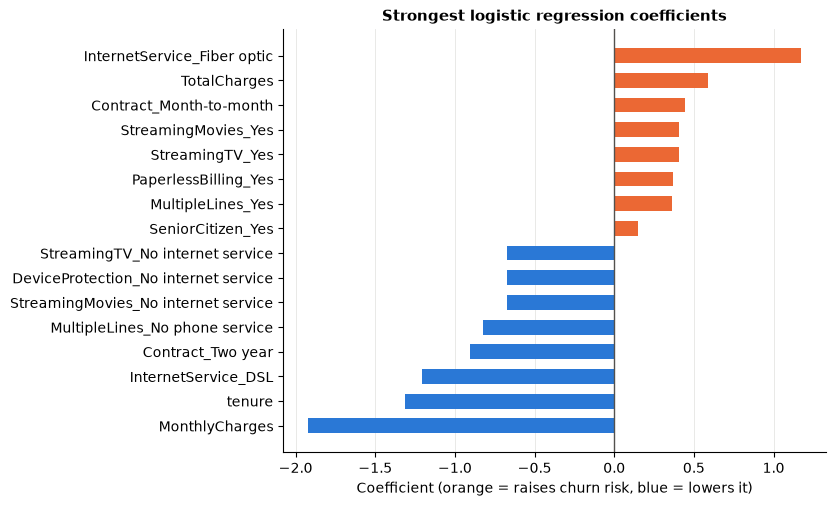

,coefficient,odds_ratio
MonthlyCharges,-1.923,0.146
tenure,-1.314,0.269
InternetService_DSL,-1.208,0.299
Contract_Two year,-0.904,0.405
MultipleLines_No phone service,-0.824,0.439
StreamingMovies_No internet service,-0.671,0.511
DeviceProtection_No internet service,-0.671,0.511
StreamingTV_No internet service,-0.671,0.511
SeniorCitizen_Yes,0.150,1.161
MultipleLines_Yes,0.361,1.434


In [3]:
feature_names = pipeline.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.DataFrame({
    "coefficient": pipeline.named_steps["model"].coef_[0],
}, index=[name.split("__", 1)[1] for name in feature_names])
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.sort_values("coefficient")

top = pd.concat([coefficients.head(8), coefficients.tail(8)])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top["coefficient"],
        color=np.where(top["coefficient"] > 0, "#eb6834", "#2a78d6"), height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Strongest logistic regression coefficients",
       xlabel="Coefficient (orange = raises churn risk, blue = lowers it)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

top.round(3)

**Why is the `MonthlyCharges` coefficient negative when churners pay more?** Check how much of
`MonthlyCharges` is simply determined by the services a customer subscribes to:

In [4]:
from sklearn.linear_model import LinearRegression

service_cols = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_dummies = pd.get_dummies(X_train[service_cols], drop_first=True)
r2 = LinearRegression().fit(service_dummies, X_train["MonthlyCharges"]).score(service_dummies, X_train["MonthlyCharges"])
print(f"R² of MonthlyCharges explained by the service columns (train): {r2:.4f}")

R² of MonthlyCharges explained by the service columns (train): 0.9988


**Observations**
- **Increase risk:** Fiber optic (odds ×3.2), month-to-month contract, paperless billing, streaming services,
  multiple lines, senior citizen.
- **Decrease risk:** longer tenure, DSL, two-year contract, no internet service.
- **Counter-intuitive signs** — `MonthlyCharges` is *negative* and `TotalCharges` *positive*, although EDA showed
  churners pay more per month and have lower totals. The check above shows the services explain **99.9% of
  `MonthlyCharges`**, and `TotalCharges` ≈ tenure × MonthlyCharges. The model splits credit between these near-duplicate
  inputs, so the **individual signs of these numeric coefficients are not interpretable**. Only their combined effect
  is meaningful. This is a textbook multicollinearity effect: it hurts interpretation, not prediction.
- Business conclusions are therefore based on the **EDA patterns + permutation importance**, not on single coefficients.

## 3. How should the business use the scores? Risk-based targeting

Rank the test customers by predicted churn probability and split them into 10 equal groups (deciles).
If the model is useful, the top deciles should contain far more churners than the bottom ones.

In [5]:
scored = pd.DataFrame({"churn_probability": pipeline.predict_proba(X_test)[:, 1], "churned": y_test.values})
scored = scored.sort_values("churn_probability", ascending=False).reset_index(drop=True)
scored["risk_decile"] = pd.qcut(scored.index, 10, labels=range(1, 11))   # 1 = highest risk

deciles = scored.groupby("risk_decile", observed=True).agg(
    customers=("churned", "size"),
    min_probability=("churn_probability", "min"),
    actual_churn_rate=("churned", "mean"),
    churners=("churned", "sum"),
)
deciles["cumulative_share_of_churners"] = deciles["churners"].cumsum() / deciles["churners"].sum()
deciles.round(3)

,customers,min_probability,actual_churn_rate,churners,cumulative_share_of_churners
risk_decile,,,,,
1,141,0.661,0.738,104,0.278
2,141,0.529,0.574,81,0.495
3,141,0.420,0.411,58,0.650
4,141,0.277,0.326,46,0.773
5,141,0.193,0.255,36,0.869
6,140,0.113,0.171,24,0.933
7,141,0.062,0.121,17,0.979
8,141,0.031,0.028,4,0.989
9,141,0.010,0.014,2,0.995


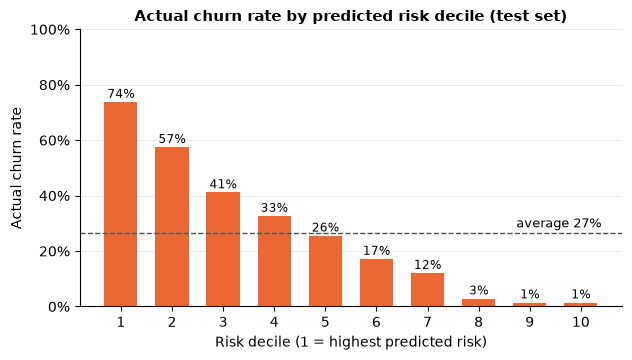

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(deciles.index.astype(str), deciles["actual_churn_rate"], color="#eb6834", width=0.65)
ax.axhline(y_test.mean(), color="#52514e", linestyle="--", linewidth=1)
ax.text(9.4, y_test.mean() + 0.02, f"average {y_test.mean():.0%}", ha="right", fontsize=9)
for i, rate in enumerate(deciles["actual_churn_rate"]):
    ax.text(i, rate + 0.015, f"{rate:.0%}", ha="center", fontsize=8.5)
ax.set(title="Actual churn rate by predicted risk decile (test set)",
       xlabel="Risk decile (1 = highest predicted risk)", ylabel="Actual churn rate", ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.show()

**Observations**
- Decile 1 (top 10% risk) has an actual churn rate of **73.8%**, vs **26.5% on average** → 2.8× more churners than random targeting.
- The **top 20%** of customers by risk contain **49.5%** of all churners; the **top 30%** contain **65.0%**.
- The bottom three deciles have churn rates of only 1–3%: these customers need no retention spend.
- **Practical use:** if the budget covers only part of the base, contact customers **in order of risk**. The 0.25 threshold
  (about the top ~43%) is one operating point; a smaller budget simply means stopping earlier in the ranking.

## 4. Summary

### Main churn patterns (from EDA — associations, not proven causes)
| Pattern | Evidence |
|---|---|
| Month-to-month contracts churn most | 42.7% vs 11.3% (1-year) and 2.8% (2-year) |
| Risk is highest early in the relationship | 52.9% churn in the first 6 months vs 6.6% after 5 years |
| Fiber optic customers churn more | 41.9% vs 19.0% DSL; they also pay the most (median 91.7/month) |
| Customers without security / tech support churn more | Fiber + no TechSupport 49.4% vs 22.6% with it |
| Electronic check payers churn more | 45.3% vs 15–19% for other methods |
| Gender and phone service don't matter | spread < 2 percentage points |

### Final model
Logistic Regression (scaled numeric + one-hot categorical features), decision threshold 0.25.
**Test set:** ROC-AUC 0.842, recall 0.813, precision 0.499, F1 0.619. The top 20% risk group contains ~50% of churners.

### Actionable recommendations (to be validated with experiments)
1. **Target new month-to-month customers** with onboarding support and an incentive to move to a 1- or 2-year
   contract. This is the highest-risk segment (51% churn in the first year on month-to-month).
2. **Investigate the fiber optic experience** (price, reliability, competitor offers). The high churn of fiber
   customers is a strong signal, but its cause is unknown from this data.
3. **Bundle or promote OnlineSecurity / TechSupport** for fiber customers, and test whether it reduces churn
   (it is associated with lower churn, but customers who choose it may just be more engaged).
4. **Encourage automatic payment methods** (e.g. a small discount for switching from electronic check), then measure the effect.
5. **Use the model's ranking** to prioritise retention spend: start with the top-risk deciles and stop where
   the expected value of an intervention falls below its cost.

### Limitations
- **Snapshot data, no time dimension:** we can't see *when* behaviour changed before churn, and validation was a
  random split, not a time-based one. Performance on future customers may differ.
- **Missing important drivers:** no data on customer-service interactions, complaints, network quality, pricing
  changes or competitor offers.
- **No cost data:** the threshold relies on the assumption that missing a churner costs more than a wasted offer.
- **Moderate precision:** about half of flagged customers would have stayed anyway.
- **Correlated features** limit how far individual coefficients can be interpreted.
- **Associations only:** the model predicts *who* is likely to leave, not *why*, and not whether an intervention will work.

### Possible future improvements
- Collect behavioural / time-based data (usage trends, support tickets, billing changes) and validate with a time-based split.
- Obtain intervention costs and customer lifetime value, then pick the threshold by **expected profit**.
- Calibrate probabilities (e.g. `CalibratedClassifierCV`) if they will be used as exact risk percentages.
- Run A/B tests of retention actions to move from correlation to causal evidence (uplift modelling).
- Monitor model performance and data drift after deployment, and retrain periodically.